# PEFT vs prompting (primary model)

Compares the fine-tuned (QLoRA) Qwen models with zero-shot and five-shot prompting of the same base model.
Everything is scored by the same code (`parse_prediction` + `compute_metrics`): prompting by
`run_prompting.py`, PEFT by `rescore_predictions.py`.

1. checks (all files present, same texts, same demonstration IDs)
2. main table
3. paired bootstrap: which differences are real?
4. per-emotion F1 for all conditions
5. label counts and label distribution
6. which texts are hard for every condition
7. Swedish texts without å/ä/ö

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from llm_project.prompting import LABELS, DEFAULT_VARIANT

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load((PROJECT_ROOT / "configs" / "prompting.yaml").read_text(encoding="utf-8"))

SPLIT = "dev"
MODEL = cfg.get("models", [{}])[0].get("name", "Qwen2.5-3B-Instruct").split("/")[-1]
PEFT_EXPERIMENT = "baseline_qlora_qv"
ID_KEY = cfg.get("prompting", {}).get("id_key", "alignment_id")

LABELS = LABELS
CONDITIONS = {
    "zero-shot": ("prompting", "zero_shot", "default"),
    "five-shot": ("prompting", "five_shot", "default"),
    "PEFT (EN-trained)": ("peft", "peft-english", PEFT_EXPERIMENT),
    "PEFT (SV-trained)": ("peft", "peft-target", PEFT_EXPERIMENT),
    "PEFT (bilingual)": ("peft", "peft-bilingual", PEFT_EXPERIMENT),
}

PRED = PROJECT_ROOT / "outputs" / "predictions"
METRICS = PROJECT_ROOT / "outputs" / "metrics"
pd.set_option("display.precision", 3)

LANGS = ["en", cfg.get("language", "sv")]

## 1. Checks

In [2]:
from llm_project.notebook_utils import compare_predictions, load_preds, load_metrics


def run_name(lang, cond):
    family, c, v = CONDITIONS[cond]
    return family, c, v


def try_load_preds(lang, cond):
    family, c, v = run_name(lang, cond)
    path_dir = PRED / family / SPLIT
    path = path_dir / f"{MODEL}__{lang}__{c}__{v}.jsonl"
    if not path.exists():
        return None
    return load_preds(MODEL, lang, c, path_dir, variant=v).set_index(ID_KEY)


def try_load_metrics(lang, cond):
    family, c, v = run_name(lang, cond)
    path_dir = METRICS / family / SPLIT
    path = path_dir / f"{MODEL}__{lang}__{c}__{v}.json"
    return load_metrics(MODEL, lang, c, path_dir, variant=v) if path.exists() else None


available = {(l, c): try_load_preds(l, c) for l in LANGS for c in CONDITIONS}
available = {k: v for k, v in available.items() if v is not None}
print("Runs found:")
for (l, c), df in available.items():
    print(f"  {l}  {c:18s} n={len(df)}")
print(
    "Not found (expected: PEFT (SV-trained) on English):",
    [f"{l}/{c}" for l in LANGS for c in CONDITIONS if (l, c) not in available],
)

for l in LANGS:
    ids = [set(df.index) for (ll, _), df in available.items() if ll == l]
    assert all(s == ids[0] for s in ids), f"{l}: runs cover different texts"

fs = [try_load_metrics(l, "five-shot") for l in LANGS]
fs = [m for m in fs if m]
print("five-shot IDs:", {tuple(m["five_shot_ids"]) for m in fs})
print("fingerprints:", {m.get("fingerprint") for m in fs})
assert len({tuple(m["five_shot_ids"]) for m in fs}) == 1, (
    "five-shot runs used different demonstration IDs"
)

Runs found:
  en  zero-shot          n=497
  en  five-shot          n=497
  en  PEFT (EN-trained)  n=497
  en  PEFT (SV-trained)  n=497
  en  PEFT (bilingual)   n=497
  sv  zero-shot          n=497
  sv  five-shot          n=497
  sv  PEFT (EN-trained)  n=497
  sv  PEFT (SV-trained)  n=497
  sv  PEFT (bilingual)   n=497
Not found (expected: PEFT (SV-trained) on English): []
five-shot IDs: {('en/1990/100530/5989398.xml.gz#575', 'en/1965/59309/6919338.xml.gz#1621', 'en/1954/46754/6980377.xml.gz#1659', 'en/2015/4428728/6758675.xml.gz#636', 'en/1965/59309/6919338.xml.gz#1231')}
fingerprints: {'091255db13ac2d57'}


## 2. Main table
Primary metric: macro-F1. `labels/text` should be compared with the gold average.

macro_f1  micro_f1  samples_f1  jaccard  exact_match  \
lang condition                                                                 
en   zero-shot             0.302     0.331       0.303    0.271        0.187   
     five-shot             0.390     0.418       0.391    0.332        0.167   
     PEFT (EN-trained)     0.433     0.462       0.452    0.405        0.278   
     PEFT (SV-trained)     0.414     0.447       0.430    0.374        0.219   
     PEFT (bilingual)      0.429     0.456       0.447    0.399        0.268   
sv   zero-shot             0.210     0.242       0.223    0.200        0.141   
     five-shot             0.288     0.323       0.298    0.260        0.155   
     PEFT (EN-trained)     0.329     0.363       0.365    0.332        0.243   
     PEFT (SV-trained)     0.341     0.377       0.375    0.330        0.209   
     PEFT (bilingual)      0.339     0.375       0.374    0.331        0.215   

                        malformed  empty  labels/text  gold labels/text  
lang condition                                                           
en   zero-shot              0.002  0.169        0.936             1.439  
     five-shot              0.000  0.038        1.410             1.439  
     PEFT (EN-trained)      0.000  0.000        1.175             1.439  
     PEFT (SV-trained)      0.000  0.000        1.300             1.439  
     PEFT (bilingual)       0.000  0.000        1.145             1.439  
sv   zero-shot              0.000  0.175        0.855             1.439  
     five-shot              0.000  0.080        1.201             1.439  
     PEFT (EN-trained)      0.000  0.000        1.032             1.439  
     PEFT (SV-trained)      0.000  0.000        1.209             1.439  
     PEFT (bilingual)       0.000  0.000        1.137             1.439

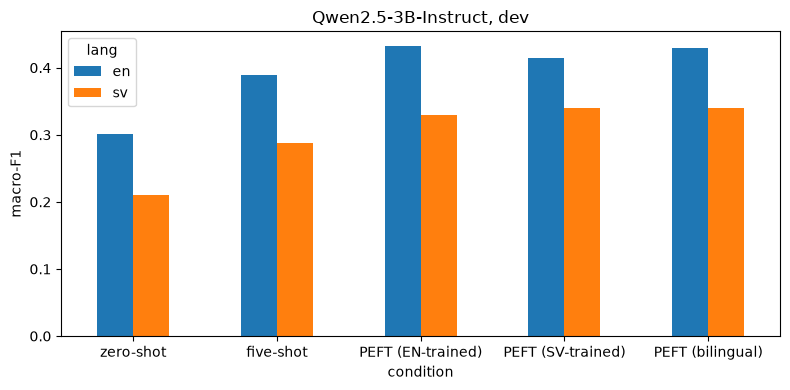

In [3]:
rows = []
for l, c in available:
    m = try_load_metrics(l, c)
    rows.append(
        {
            "lang": l,
            "condition": c,
            "macro_f1": m["macro_f1"],
            "micro_f1": m["micro_f1"],
            "samples_f1": m["samples_f1"],
            "jaccard": m["jaccard"],
            "exact_match": m["exact_match"],
            "malformed": m["malformed_rate"],
            "empty": m["empty_prediction_rate"],
            "labels/text": m["pred_label_cardinality"],
            "gold labels/text": m["gold_label_cardinality"],
        }
    )
main = pd.DataFrame(rows)
order = {c: i for i, c in enumerate(CONDITIONS)}
main = main.sort_values(
    ["lang", "condition"], key=lambda s: s.map(order) if s.name == "condition" else s
)
display(main.set_index(["lang", "condition"]))

ax = (
    main.pivot(index="condition", columns="lang", values="macro_f1")
    .reindex(list(CONDITIONS))
    .plot.bar(rot=0, figsize=(8, 4))
)
ax.set_ylabel("macro-F1")
ax.set_title(f"Qwen2.5-3B-Instruct, {SPLIT}")
plt.tight_layout()
plt.show()

## 3. Paired bootstrap

1,000 resamples of the texts; both conditions are scored on the *same* resampled texts (matched by
alignment ID). If the 95% interval excludes 0, the difference is unlikely to be noise.
The cross-lingual rows compare English and Swedish versions of the same aligned texts.

In [4]:
from llm_project.notebook_utils import binarise, f1s, paired_bootstrap

comparisons = []
for l in LANGS:
    for peft in ["PEFT (EN-trained)", "PEFT (SV-trained)", "PEFT (bilingual)"]:
        for base in ["zero-shot", "five-shot"]:
            comparisons.append((f"{peft} vs {base}", (l, base), (l, peft)))
comparisons += [
    ("SV-trained vs EN-trained (on SV)", ("sv", "PEFT (EN-trained)"), ("sv", "PEFT (SV-trained)")),
    ("bilingual vs EN-trained (on SV)", ("sv", "PEFT (EN-trained)"), ("sv", "PEFT (bilingual)")),
    ("bilingual vs SV-trained (on SV)", ("sv", "PEFT (SV-trained)"), ("sv", "PEFT (bilingual)")),
    ("bilingual vs EN-trained (on EN)", ("en", "PEFT (EN-trained)"), ("en", "PEFT (bilingual)")),
]
for c in CONDITIONS:
    comparisons.append((f"SV vs EN | {c}", ("en", c), ("sv", c)))

rows = []
for name, a, b in comparisons:
    if a not in available or b not in available:
        continue
    d, lo, hi, n = paired_bootstrap(available[a], available[b], labels=LABELS)
    rows.append(
        {
            "comparison": name,
            "lang (A -> B)": f"{a[0]} -> {b[0]}",
            "macro_f1 diff (B-A)": d,
            "ci_low": lo,
            "ci_high": hi,
            "significant": not (lo <= 0 <= hi),
            "n": n,
        }
    )
boot = pd.DataFrame(rows)
boot

,comparison,lang (A -> B),macro_f1 diff (B-A),ci_low,ci_high,significant,n
0,PEFT (EN-trained) vs zero-shot,en -> en,0.131,9.154e-02,0.170,True,497
1,PEFT (EN-trained) vs five-shot,en -> en,0.043,6.834e-03,0.081,True,497
2,PEFT (SV-trained) vs zero-shot,en -> en,0.113,7.145e-02,0.152,True,497
3,PEFT (SV-trained) vs five-shot,en -> en,0.025,-1.526e-02,0.064,False,497
4,PEFT (bilingual) vs zero-shot,en -> en,0.128,8.479e-02,0.169,True,497
5,PEFT (bilingual) vs five-shot,en -> en,0.040,4.060e-04,0.079,True,497
6,PEFT (EN-trained) vs zero-shot,sv -> sv,0.119,7.894e-02,0.157,True,497
7,PEFT (EN-trained) vs five-shot,sv -> sv,0.041,5.094e-03,0.079,True,497
8,PEFT (SV-trained) vs zero-shot,sv -> sv,0.130,9.129e-02,0.168,True,497
9,PEFT (SV-trained) vs five-shot,sv -> sv,0.053,1.394e-02,0.090,True,497


## 4. Per-emotion F1
Which emotions does fine-tuning improve, and which transfer from English to Swedish?

en                                                \
             zero-shot five-shot PEFT (EN-trained) PEFT (SV-trained)   
anger            0.321     0.483             0.583             0.567   
anticipation     0.388     0.467             0.506             0.523   
disgust          0.176     0.387             0.339             0.348   
fear             0.209     0.356             0.355             0.291   
joy              0.317     0.449             0.551             0.527   
sadness          0.422     0.451             0.470             0.400   
surprise         0.180     0.086             0.293             0.339   
trust            0.400     0.438             0.365             0.320   

                                     sv                              \
             PEFT (bilingual) zero-shot five-shot PEFT (EN-trained)   
anger                   0.574     0.170     0.375             0.392   
anticipation            0.525     0.280     0.387             0.426   
disgust                 0.331     0.028     0.330             0.051   
fear                    0.396     0.053     0.133             0.299   
joy                     0.535     0.240     0.434             0.466   
sadness                 0.420     0.389     0.279             0.463   
surprise                0.339     0.262     0.043             0.306   
trust                   0.314     0.258     0.323             0.231   

                                                gold_support_sv  
             PEFT (SV-trained) PEFT (bilingual)                  
anger                    0.434            0.434             125  
anticipation             0.514            0.513             119  
disgust                  0.241            0.197              67  
fear                     0.330            0.333              67  
joy                      0.459            0.456              77  
sadness                  0.341            0.373              89  
surprise                 0.177            0.188              84  
trust                    0.228            0.220              87

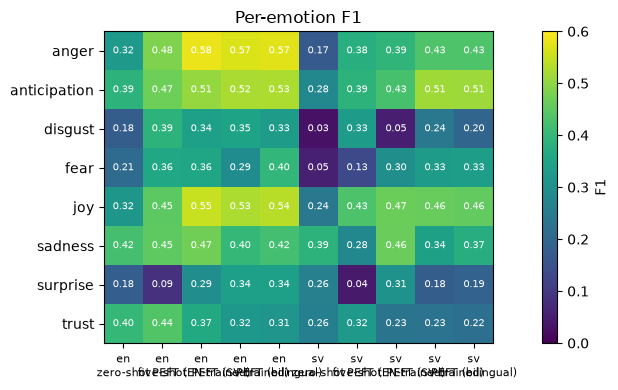

In [5]:
per = {}
for l, c in available:
    m = try_load_metrics(l, c)
    per[(l, c)] = {e: m["per_label"][e]["f1"] for e in LABELS}
per = pd.DataFrame(per)[[k for l in LANGS for k in [(l, c) for c in CONDITIONS] if k in available]]
first = next(iter(available))
per["gold_support_sv"] = (
    [try_load_metrics("sv", "zero-shot")["per_label"][e]["support"] for e in LABELS]
    if ("sv", "zero-shot") in available
    else np.nan
)
display(per)

f1_only = per.drop(columns="gold_support_sv")
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(f1_only.values, cmap="viridis", vmin=0, vmax=max(0.6, np.nanmax(f1_only.values)))
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xticks(range(f1_only.shape[1]), [f"{l}\n{c}" for l, c in f1_only.columns], fontsize=8)
for i in range(f1_only.shape[0]):
    for j in range(f1_only.shape[1]):
        ax.text(j, i, f"{f1_only.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im, label="F1")
ax.set_title("Per-emotion F1")
plt.tight_layout()
plt.show()

## 5. Label counts and label distribution
How often each emotion is predicted, against how often it is gold.

In [6]:
for l in LANGS:
    runs = {c: available[(l, c)] for c in CONDITIONS if (l, c) in available}
    if not runs:
        continue
    gold = next(iter(runs.values()))["gold"]
    table = {
        "GOLD": pd.Series([e for g in gold for e in g]).value_counts().reindex(LABELS, fill_value=0)
    }
    for c, df in runs.items():
        table[c] = (
            pd.Series([e for p in df["pred"] for e in p])
            .value_counts()
            .reindex(LABELS, fill_value=0)
        )
    print(f"--- {l}: predicted counts per emotion ---")
    display(pd.DataFrame(table))

--- en: predicted counts per emotion ---


,GOLD,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained),PEFT (bilingual)
anger,125,43,86,153,136,133
anticipation,119,144,202,142,210,159
disgust,67,24,119,57,88,60
fear,67,19,34,40,36,44
joy,77,24,61,61,52,50
sadness,89,91,53,60,46,49
surprise,84,27,9,32,40,40
trust,87,93,137,39,38,34


--- sv: predicted counts per emotion ---


,GOLD,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained),PEFT (bilingual)
anger,125,28,83,135,165,156
anticipation,119,81,165,78,161,154
disgust,67,4,121,12,66,55
fear,67,8,8,40,36,41
joy,77,23,66,99,71,59
sadness,89,91,47,75,46,45
surprise,84,99,8,40,29,33
trust,87,91,99,34,27,22


## 6. Hard texts: wrong for every condition
Texts that no condition gets exactly right are often texts without an emotional cue (context lost from the film).

In [7]:
for l in LANGS:
    runs = {c: available[(l, c)] for c in CONDITIONS if (l, c) in available}
    if len(runs) < 2:
        continue
    ids = next(iter(runs.values())).index
    exact = pd.DataFrame(
        {
            c: [set(df.at[i, "gold"]) == set(df.at[i, "pred"]) for i in ids]
            for c, df in runs.items()
        },
        index=ids,
    )
    print(f"--- {l}: texts exactly right per number of conditions ---")
    print(exact.sum(axis=1).value_counts().sort_index().to_string())
    hard = exact.index[~exact.any(axis=1)]
    print(f"{len(hard)} of {len(ids)} texts are wrong in every condition. Sample:")
    first_df = next(iter(runs.values()))
    with pd.option_context("display.max_colwidth", 90):
        display(
            first_df.loc[hard[:10], ["text", "gold"]].assign(
                **{c: runs[c].loc[hard[:10], "pred"] for c in runs}
            )
        )

--- en: texts exactly right per number of conditions ---
0    289
1     68
2     34
3     39
4     32
5     35
289 of 497 texts are wrong in every condition. Sample:


,text,gold,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained),PEFT (bilingual)
alignment_id,,,,,,,
en/1954/46754/6980377.xml.gz#1010,"I got him sold, Harry.",[joy],[anticipation],"[anticipation, joy]",[anticipation],[anticipation],[anticipation]
en/1954/46754/6980377.xml.gz#1330,"But no more odd, surely, than my driving away that day, away from her, knowing that, i...",[trust],[sadness],"[anticipation, sadness]",[sadness],"[anticipation, sadness]",[sadness]
en/1954/46754/6980377.xml.gz#1335,You've cost me millions and millions of francs.,"[anger, disgust, sadness]",[anger],"[anger, disgust]",[anger],"[anger, disgust]",[anger]
en/1954/46754/6980377.xml.gz#1447,That to marry Maria would be the most senselessly cruel and destructive thing you will...,"[anger, fear, surprise]",[disgust],"[disgust, fear]","[anger, disgust]","[anger, disgust]","[anger, disgust]"
en/1954/46754/6980377.xml.gz#1458,Perhaps that's why I'm incapable of having a child.,[fear],[sadness],[sadness],[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#1564,"Oh, no, no, no.","[anticipation, surprise]",[sadness],"[disgust, sadness]",[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#1606,I do not know who plays the violin.,"[anticipation, fear]",[],[],[surprise],[surprise],[surprise]
en/1954/46754/6980377.xml.gz#1655,"Emotionally, she's a child.",[anger],[sadness],[sadness],[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#1753,Do you understand now why it is so important to me for you to believe that I love you ...,[joy],[trust],"[anticipation, joy, trust]","[anticipation, joy]","[anticipation, joy]","[anticipation, joy]"


--- sv: texts exactly right per number of conditions ---
0    308
1     56
2     38
3     48
4     32
5     15
308 of 497 texts are wrong in every condition. Sample:


,text,gold,zero-shot,five-shot,PEFT (EN-trained),PEFT (SV-trained),PEFT (bilingual)
alignment_id,,,,,,,
en/1954/46672/4170335.xml.gz#39,Inget passande ställe för en prästson.,"[anger, disgust]",[sadness],[disgust],[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#1010,Jag knep honom.,[joy],[surprise],[disgust],[anger],[anger],[anger]
en/1954/46754/6980377.xml.gz#1174,Om det hade hjälpt hade jag skrikit det pa gatorna.,[anger],[surprise],"[anger, anticipation, disgust]",[fear],"[anger, disgust]","[anger, disgust]"
en/1954/46754/6980377.xml.gz#1300,Han är mindre gigolo än nagon i vart sällskap.,[trust],[surprise],[disgust],[joy],[disgust],[disgust]
en/1954/46754/6980377.xml.gz#1330,"Men det är inte underligare än att jag den dagen körde vidare, bort fran henne i vetsk...",[trust],[surprise],"[anticipation, sadness]","[anticipation, joy]","[anticipation, joy]","[anticipation, fear]"
en/1954/46754/6980377.xml.gz#1335,Du har kostat mig miljoner franc.,"[anger, disgust, sadness]",[sadness],"[anger, disgust]",[anger],[anger],[anger]
en/1954/46754/6980377.xml.gz#1434,- Det har jag insett.,[anticipation],[],[sadness],[sadness],[sadness],[sadness]
en/1954/46754/6980377.xml.gz#1447,Att gifta dig med Maria skulle vara det mest destruktiva du kan göra?,"[anger, fear, surprise]","[anger, trust]",[disgust],[fear],[fear],[fear]
en/1954/46754/6980377.xml.gz#1458,Kanske är det därför jag inte kan fa barn.,[fear],[sadness],"[sadness, trust]",[anger],[anticipation],[anticipation]


## 7. Swedish texts without å/ä/ö
Some subtitles lost their diacritics (e.g. *grata* for *gråta*). Does that hurt accuracy?

In [8]:
if ("sv", "zero-shot") in available:
    sv_text = available[("sv", "zero-shot")]["text"]
    no_diacritics = ~sv_text.str.lower().str.contains("[åäö]")
    print(
        f"{no_diacritics.sum()} of {len(sv_text)} Swedish texts contain no å/ä/ö "
        "(includes texts that simply don't need them)"
    )
    rows = []
    for c in CONDITIONS:
        if ("sv", c) not in available:
            continue
        df = available[("sv", c)]
        for flag, label in [(no_diacritics, "no å/ä/ö"), (~no_diacritics, "has å/ä/ö")]:
            sub = df[flag.reindex(df.index).values]
            rows.append(
                {
                    "condition": c,
                    "group": label,
                    "n": len(sub),
                    "macro_f1": f1s(binarise(sub["gold"], LABELS), binarise(sub["pred"], LABELS))[0],                }
            )
    display(pd.DataFrame(rows).pivot(index="condition", columns="group", values="macro_f1"))
    with pd.option_context("display.max_colwidth", 90):
        display(sv_text[no_diacritics].head(20).to_frame())

94 of 497 Swedish texts contain no å/ä/ö (includes texts that simply don't need them)


group,has å/ä/ö,no å/ä/ö
condition,,
PEFT (EN-trained),0.333,0.306
PEFT (SV-trained),0.345,0.316
PEFT (bilingual),0.345,0.306
five-shot,0.296,0.238
zero-shot,0.216,0.161


,text
alignment_id,
en/1954/46754/6980377.xml.gz#1010,Jag knep honom.
en/1954/46754/6980377.xml.gz#1317,Ett universellt botemedel.
en/1954/46754/6980377.xml.gz#1335,Du har kostat mig miljoner franc.
en/1954/46754/6980377.xml.gz#1434,- Det har jag insett.
en/1954/46754/6980377.xml.gz#46,Dansar hon inte mer?
en/1954/46754/6980377.xml.gz#492,Han kan inte diskutera hennes framtid just nu.
en/1954/46754/6980377.xml.gz#766,Det ljusnade da Marias kanalje till bror gav sitt vittnesmal.
en/1954/46816/4245477.xml.gz#1236,- Tyckte ni om kapten Queeg?
en/1954/46816/4245477.xml.gz#806,- Paynter?


In [9]:
from llm_project.notebook_utils import compare_predictions
# test if peft is better/worse than prompting, and if sv-trained is better than en-trained on sv


def compare_examples(lang, peft, base="five-shot", k=10):
    if (lang, peft) not in available or (lang, base) not in available:
        print(f"skip: {lang} / {peft} vs {base} not available")
        return None

    base_df = available[(lang, base)]
    cand_df = available[(lang, peft)]
    english_base = available[("en", base)] if lang != "en" and ("en", base) in available else None
    return compare_predictions(
        base_df,
        cand_df,
        base_name=base,
        candidate_name=peft,
        k=k,
        english_df=english_base,
    )


qual = {}
for lang, peft, base in [
    ("sv", "PEFT (SV-trained)", "five-shot"),
    ("sv", "PEFT (bilingual)", "five-shot"),
    ("en", "PEFT (EN-trained)", "five-shot"),
    ("sv", "PEFT (SV-trained)", "PEFT (EN-trained)"),
]:
    qual[(lang, peft, base)] = compare_examples(lang, peft, base=base)

=== PEFT (SV-trained) vs five-shot | improved 128, worsened 83, same 286 ===
Candidate IMPROVED:


,text,gold,five-shot,PEFT (SV-trained),delta,english_text
alignment_id,,,,,,
en/1954/46816/4245477.xml.gz#806,- Paynter?,[surprise],[],[surprise],1.0,- Painter?
en/2017/6394858/6932863.xml.gz#141,Har du aldrig polisanmält honom?,[surprise],[anger],[surprise],1.0,"Wait, and you never went to the cops after all these years."
en/2012/1829012/5779744.xml.gz#1282,Han går ut och köper en bukett rosor.,[anticipation],[joy],[anticipation],1.0,- So he goes out and he buys a bunch of roses.
en/2017/6398054/7016299.xml.gz#1059,"Jag vill inte att det händer min syster, eller dina barn, eller nästa unge.",[fear],"[anticipation, sadness]",[fear],1.0,"I just don't want it to happen to my sisters, or your kids, or the next kid."
en/2015/4428184/6361946.xml.gz#87,Dödade Trubel Juliette?,[surprise],[disgust],[surprise],1.0,Trubel killed Juliette?
en/1954/46816/4245477.xml.gz#1595,Han hade inte hört talas om Queeg.,[surprise],[anticipation],[surprise],1.0,He never even heard of Queeg.
en/1954/46754/6980377.xml.gz#1655,Emotionellt är hon ett barn.,[anger],[sadness],[anger],1.0,"Emotionally, she's a child."
en/2017/6398054/7016299.xml.gz#354,Jag ville klandra mig själv för det.,[sadness],[disgust],[sadness],1.0,"You know, I wanted to blame myself for that."
en/1954/46816/4245477.xml.gz#49,- Jag har bara 48 timmar på mig.,[fear],"[anticipation, sadness]",[fear],1.0,- I've only got 48 hours.


Candidate WORSENED:


,text,gold,five-shot,PEFT (SV-trained),delta,english_text
alignment_id,,,,,,
en/1954/46816/4245477.xml.gz#1147,Ni är en stor sjöhjälte.,[trust],[trust],[joy],-1.0,You're a great naval hero.
en/1954/46816/4245477.xml.gz#1236,- Tyckte ni om kapten Queeg?,[anticipation],[anticipation],[surprise],-1.0,- Did you like Captain Queeg?
en/2015/4428184/6361946.xml.gz#525,Jag vet att du är wesen.,[trust],[trust],[anger],-1.0,I know you're Wesen.
en/2015/4425218/6174257.xml.gz#100,"jag är lessen, Nick.",[sadness],[sadness],[anger],-1.0,"I'm sorry, Nick."
en/2012/1829012/5779744.xml.gz#3,De här är urdåliga.,[disgust],[disgust],[surprise],-1.0,These are terrible.
en/2012/1829012/5779744.xml.gz#400,- Hon gav mig en jättefin halsduk.,[joy],[joy],"[anger, disgust]",-1.0,She gave me a very beautiful scarf.
en/2015/4428184/6361946.xml.gz#321,"Kanske jag gör, kanske inte, men du kan bli arresterad på federala grunder o...",[anger],[anger],[fear],-1.0,"Maybe I do, maybe I don't, but you might get yourself arrested on federal ch..."
en/2015/4425218/6174257.xml.gz#123,Du behöver en nån.,[trust],[trust],[sadness],-1.0,You need a somebody.
en/2012/1829012/5779744.xml.gz#1196,Varför gömde du bevisen?,[disgust],[disgust],[anger],-1.0,Why were you hiding the evidence?


=== PEFT (bilingual) vs five-shot | improved 127, worsened 81, same 289 ===
Candidate IMPROVED:


,text,gold,five-shot,PEFT (bilingual),delta,english_text
alignment_id,,,,,,
en/2015/4428184/6361946.xml.gz#563,Jag såg samma bok i hennes rum.,[surprise],[],[surprise],1.0,I saw the same book in her room.
en/2015/4425218/6174257.xml.gz#531,Öh-oh.,[fear],[surprise],[fear],1.0,Uh-oh.
en/1990/100240/5865478.xml.gz#241,"Det talas om en slott, formad som en hand.",[anticipation],[],[anticipation],1.0,People talk about a castle shaped like a hand.
en/1990/100212/6671913.xml.gz#1371,-Vi ska vara kanadensare!,[anticipation],"[joy, trust]",[anticipation],1.0,-We get to be Canadians!
en/1990/100212/6671913.xml.gz#911,"Och vad är ""chicken vol-au-vent""?",[surprise],[],[surprise],1.0,"And what is this ""chicken vol-au-vent""?"
en/1965/59309/6919338.xml.gz#233,- Ubåtskaptenerna skulle jubla.,[anticipation],[joy],[anticipation],1.0,- That'd be an invitation to enemy subs.
en/1965/59309/6919338.xml.gz#2015,Två jagare skadade av minor.,[sadness],[],[sadness],1.0,Two destroyers hit by mines...
en/1965/59309/6919338.xml.gz#1671,- Det kan vara värre än så.,[fear],"[anger, anticipation]",[fear],1.0,- That might not be the worst of it.
en/1965/59309/6919338.xml.gz#1646,Han ska beskriva planen för er.,[anticipation],[],[anticipation],1.0,He'll lay out the plan of operation for you.


... (6 outputs left out)

=== PEFT (SV-trained) vs PEFT (EN-trained) | improved 68, worsened 66, same 363 ===
Candidate IMPROVED:


,text,gold,PEFT (EN-trained),PEFT (SV-trained),delta,english_text
alignment_id,,,,,,
en/1990/100530/5989398.xml.gz#1377,Nu mina nyheter.,[anticipation],[anger],[anticipation],1.0,"Now, my news."
en/1954/46816/4245477.xml.gz#1094,- Jag är vän till familjen.,[trust],[joy],[trust],1.0,- I'm a friend of the family.
en/1965/59309/6919338.xml.gz#1187,Är era män redo för en luftlandsättning?,[anticipation],[surprise],[anticipation],1.0,"Colonel, your men in shape for a parachute drop?"
en/2012/1829012/5779744.xml.gz#208,Du är chockad för att jag snodde äran för din idé.,[anger],[joy],[anger],1.0,And you're shocked because I took credit for your idea.
en/1965/59309/6919338.xml.gz#233,- Ubåtskaptenerna skulle jubla.,[anticipation],[joy],[anticipation],1.0,- That'd be an invitation to enemy subs.
en/1990/100404/5649520.xml.gz#1316,- Inte öppet för diskussion.,[anger],[anticipation],[anger],1.0,"It's not negotiable, Sandy."
en/1990/100404/5649520.xml.gz#1329,- Staten kallar inspektör Morris Dickerman.,[anticipation],[anger],[anticipation],1.0,The State calls Detective Morris Dickerman.
en/1965/59309/6919338.xml.gz#615,"Jag blir placerad långt fram, men knappast i stridszonen.",[anticipation],[anger],[anticipation],1.0,"I expect to be in the forward areas, if not actually in combat."
en/1990/100507/58167.xml.gz#854,-Tommy Gunn!,[surprise],[anger],[surprise],1.0,- Tommy Gunn!


Candidate WORSENED:


,text,gold,PEFT (EN-trained),PEFT (SV-trained),delta,english_text
alignment_id,,,,,,
en/1954/46816/4245477.xml.gz#1332,"- Ja, det ingår i bilden.",[trust],[trust],[anticipation],-1.0,- That's part of the picture.
en/1954/46816/4245477.xml.gz#1147,Ni är en stor sjöhjälte.,[trust],[trust],[joy],-1.0,You're a great naval hero.
en/1954/46816/4245477.xml.gz#706,Han knäcks när som helst.,[fear],[fear],[sadness],-1.0,He'll snap any day.
en/2015/4425218/6174257.xml.gz#531,Öh-oh.,[fear],[fear],[anticipation],-1.0,Uh-oh.
en/2012/1829012/5779744.xml.gz#1258,- Var ni hennes gäst?,[surprise],[surprise],[anticipation],-1.0,- Were you a guest?
en/2015/4425218/6174257.xml.gz#100,"jag är lessen, Nick.",[sadness],[sadness],[anger],-1.0,"I'm sorry, Nick."
en/2015/4428184/6361946.xml.gz#563,Jag såg samma bok i hennes rum.,[surprise],[surprise],[anticipation],-1.0,I saw the same book in her room.
en/2015/4428184/6361946.xml.gz#525,Jag vet att du är wesen.,[trust],[trust],[anger],-1.0,I know you're Wesen.
en/2015/4425218/6174257.xml.gz#614,"Nick gjorde allt han kunde, men dom kom undan.",[sadness],[sadness],"[anger, disgust]",-1.0,"Nick did everything he could, but they got away."
